In [1]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 55.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 7.7 MB/s eta 0:00:00


In [2]:
from ultralytics import YOLO
import os
import zipfile
import shutil
import random
import requests
import json

print("Ultralytics YOLO imported successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics YOLO imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving Cucumber Datasets.v2i.openai.zip to Cucumber Datasets.v2i.openai.zip


In [4]:
zip_file = list(uploaded.keys())[0]

raw_dataset = "/content/cucumber_raw"

os.makedirs(raw_dataset, exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(raw_dataset)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [5]:
for root, dirs, files_list in os.walk(raw_dataset):
    for file in files_list[:10]:
        print(os.path.join(root, file))

/content/cucumber_raw/_annotations.train.jsonl
/content/cucumber_raw/_annotations.valid.jsonl
/content/cucumber_raw/README.roboflow.txt
/content/cucumber_raw/README.dataset.txt
/content/cucumber_raw/_annotations.test.jsonl


In [6]:
import os
import json

jsonl_files = [
    "_annotations.train.jsonl",
    "_annotations.valid.jsonl",
    "_annotations.test.jsonl"
]

all_data = []

for filename in jsonl_files:

    file_path = os.path.join(raw_dataset, filename)

    if not os.path.exists(file_path):
        print("Not found:", filename)
        continue

    with open(file_path, "r", encoding="utf-8") as f:

        for line in f:

            item = json.loads(line)

            messages = item["messages"]

            image_url = None
            label = None

            # Find image
            for message in messages:

                if (
                    message.get("role") == "user"
                    and isinstance(message.get("content"), list)
                ):

                    for content in message["content"]:

                        if content.get("type") == "image_url":
                            image_url = content["image_url"]["url"]

            # Get classification label
            if messages:
                label = messages[-1]["content"]

            if image_url and label:

                all_data.append({
                    "url": image_url,
                    "label": label
                })

print("Total images:", len(all_data))

Total images: 592


In [7]:
from collections import Counter

class_counts = Counter(
    item["label"] for item in all_data
)

print("Classes:")

for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

Classes:
Bad: 168
Good: 424


In [8]:
dataset_path = "/content/cucumber_classification"

classes = sorted(
    list(set(item["label"] for item in all_data))
)

print("Classes:", classes)

for split in ["train", "val", "test"]:

    for class_name in classes:

        os.makedirs(
            os.path.join(
                dataset_path,
                split,
                class_name
            ),
            exist_ok=True
        )

print("Classification folders created!")

Classes: ['Bad', 'Good']
Classification folders created!


In [9]:
from sklearn.model_selection import train_test_split

urls = [item["url"] for item in all_data]
labels = [item["label"] for item in all_data]

# 80% training
train_urls, temp_urls, train_labels, temp_labels = train_test_split(
    urls,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Remaining 20% → 10% validation + 10% testing
val_urls, test_urls, val_labels, test_labels = train_test_split(
    temp_urls,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("Training:", len(train_urls))
print("Validation:", len(val_urls))
print("Testing:", len(test_urls))

Training: 473
Validation: 59
Testing: 60


In [10]:
from tqdm import tqdm

def download_images(urls, labels, split):

    success = 0
    failed = 0

    for i, (url, label) in enumerate(
        tqdm(zip(urls, labels), total=len(urls))
    ):

        try:

            response = requests.get(
                url,
                timeout=30
            )

            if response.status_code == 200:

                image_path = os.path.join(
                    dataset_path,
                    split,
                    label,
                    f"{split}_{label}_{i}.jpg"
                )

                with open(image_path, "wb") as f:
                    f.write(response.content)

                success += 1

            else:
                failed += 1

        except Exception as e:

            failed += 1

    print(f"\n{split.upper()} complete")
    print("Downloaded:", success)
    print("Failed:", failed)

In [11]:
download_images(
    train_urls,
    train_labels,
    "train"
)

download_images(
    val_urls,
    val_labels,
    "val"
)

download_images(
    test_urls,
    test_labels,
    "test"
)

100%|██████████| 473/473 [03:07<00:00,  2.52it/s]



TRAIN complete
Downloaded: 472
Failed: 1


100%|██████████| 59/59 [00:19<00:00,  3.00it/s]



VAL complete
Downloaded: 59
Failed: 0


100%|██████████| 60/60 [00:19<00:00,  3.11it/s]


TEST complete
Downloaded: 60
Failed: 0


In [12]:
for split in ["train", "val", "test"]:

    print("\n" + split.upper())

    for class_name in classes:

        folder = os.path.join(
            dataset_path,
            split,
            class_name
        )

        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )
        ]

        print(
            f"{class_name}: {len(images)} images"
        )


TRAIN
Bad: 133 images
Good: 339 images

VAL
Bad: 17 images
Good: 42 images

TEST
Bad: 17 images
Good: 43 images


In [13]:
from ultralytics import YOLO

model = YOLO("yolov8n-cls.pt")

results = model.train(
    data=dataset_path,
    epochs=50,
    imgsz=224,
    batch=16,
    name="cucumber_classifier"
)

Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cucumber_classification, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=cucumber_classifier, nbs=64, nms=None, opset=None, o

In [14]:
metrics = model.val()

print(metrics)

Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8n-cls summary (fused): 30 layers, 1,437,442 parameters, 0 gradients, 3.3 GFLOPs
train: /content/cucumber_classification/train... found 472 images in 2 classes ✅ 
val: /content/cucumber_classification/val... found 59 images in 2 classes ✅ 
test: /content/cucumber_classification/test... found 60 images in 2 classes ✅ 
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 194.0±119.0 MB/s, size: 8.4 KB)
val: Scanning /content/cucumber_classification/val... 59 images, 0 corrupt: 100% ━━━━━━━━━━━━ 59/59 13.0Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 4/4 4.1it/s 1.0s
                   all          1          1
Speed: 0.0ms preprocess, 11.1ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7

In [15]:
best_model = YOLO(
    "/content/runs/classify/cucumber_classifier/weights/best.pt"
)

print("Best model loaded!")

Best model loaded!


In [17]:
import glob
import random

test_images = glob.glob(
    "/content/cucumber_classification/test/*/*"
)

print("Test images:", len(test_images))

random_image = random.choice(test_images)

results = best_model(
    random_image,
    verbose=False
)

result = results[0]

print("Image:", random_image)

for class_id, probability in enumerate(result.probs.data.tolist()):
    class_name = result.names[class_id]
    print(f"{class_name}: {probability:.4%}")

Test images: 60
Image: /content/cucumber_classification/test/Bad/test_Bad_24.jpg
Bad: 99.9958%
Good: 0.0042%


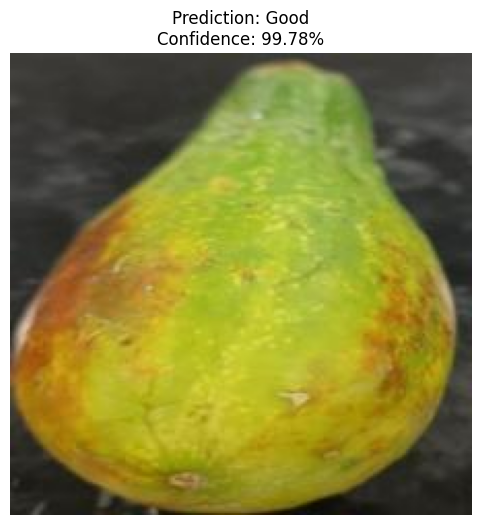

Image: /content/cucumber_classification/test/Good/test_Good_18.jpg
Prediction: Good
Confidence: 99.78%


In [20]:
from PIL import Image
import matplotlib.pyplot as plt
import glob
import random

test_images = glob.glob(
    "/content/cucumber_classification/test/*/*"
)

# Try different images until confidence is below 100%
found_image = False

random.shuffle(test_images)

for image_path in test_images:
    results = best_model(image_path, verbose=False)
    result = results[0]

    predicted_id = result.probs.top1
    confidence = result.probs.top1conf.item()
    predicted_class = result.names[predicted_id]

    # Select an image that is not 100% confidence
    if confidence < 0.9999:
        random_image = image_path
        found_image = True
        break

if found_image:
    image = Image.open(random_image)

    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.axis("off")

    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2%}"
    )

    plt.show()

    print("Image:", random_image)
    print("Prediction:", predicted_class)
    print("Confidence:", f"{confidence:.2%}")

else:
    print("All test images have confidence of approximately 100%.")

In [29]:
import os
import glob
import pandas as pd
from tqdm import tqdm

# Get images from TRAIN + VAL + TEST
all_images = []

splits = ["train", "val", "test"]

for split in splits:

    for class_name in classes:

        class_folder = os.path.join(
            dataset_path,
            split,
            class_name
        )

        images = glob.glob(
            os.path.join(class_folder, "*")
        )

        # Keep only image files
        images = [
            img for img in images
            if img.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            )
        ]

        all_images.extend(images)

print("====================================")
print("ENTIRE DATASET")
print("====================================")

print("Total images:", len(all_images))

# Show number of images per split
for split in splits:

    split_images = [
        img for img in all_images
        if os.path.basename(
            os.path.dirname(
                os.path.dirname(img)
            )
        ) == split
    ]

    print(f"{split}: {len(split_images)}")

# Show number of images per class
print("\n====================================")
print("IMAGES PER CLASS")
print("====================================")

for class_name in classes:

    count = sum(
        1 for img in all_images
        if os.path.basename(
            os.path.dirname(img)
        ) == class_name
    )

    print(f"{class_name}: {count}")

ENTIRE DATASET
Total images: 591
train: 472
val: 59
test: 60

IMAGES PER CLASS
Bad: 167
Good: 424


In [30]:
predictions = []

for image_path in tqdm(all_images, desc="Classifying all images"):

    true_label = os.path.basename(
        os.path.dirname(image_path)
    )

    results = best_model(
        image_path,
        verbose=False
    )

    result = results[0]

    predicted_id = result.probs.top1
    predicted_label = result.names[predicted_id]
    confidence = float(result.probs.top1conf)

    predictions.append({
        "Image": os.path.basename(image_path),
        "True Label": true_label,
        "Predicted Label": predicted_label,
        "Confidence": confidence,
        "Split": os.path.basename(
            os.path.dirname(
                os.path.dirname(image_path)
            )
        )
    })

df_all = pd.DataFrame(predictions)

print("====================================")
print("EVALUATION COMPLETE")
print("====================================")
print("Total images evaluated:", len(df_all))

display(df_all.head())

Classifying all images: 100%|██████████| 591/591 [00:11<00:00, 51.45it/s]


EVALUATION COMPLETE
Total images evaluated: 591


,Image,True Label,Predicted Label,Confidence,Split
0,train_Bad_16.jpg,Bad,Bad,0.999994,train
1,train_Bad_417.jpg,Bad,Bad,0.999999,train
2,train_Bad_327.jpg,Bad,Bad,0.999787,train
3,train_Bad_394.jpg,Bad,Bad,1.000000,train
4,train_Bad_27.jpg,Bad,Bad,0.999996,train


In [31]:
print(df.to_string(index=False))

           Image True Label Predicted Label  Confidence
 test_Bad_34.jpg        Bad             Bad    0.999043
 test_Bad_23.jpg        Bad             Bad    1.000000
 test_Bad_28.jpg        Bad             Bad    0.999871
 test_Bad_22.jpg        Bad             Bad    0.999511
 test_Bad_40.jpg        Bad             Bad    0.999988
 test_Bad_47.jpg        Bad             Bad    1.000000
 test_Bad_24.jpg        Bad             Bad    0.999958
 test_Bad_52.jpg        Bad             Bad    0.999992
 test_Bad_45.jpg        Bad             Bad    0.764608
 test_Bad_43.jpg        Bad             Bad    0.997198
  test_Bad_2.jpg        Bad             Bad    0.999999
 test_Bad_14.jpg        Bad             Bad    0.999965
 test_Bad_19.jpg        Bad             Bad    0.999018
  test_Bad_8.jpg        Bad             Bad    1.000000
 test_Bad_59.jpg        Bad             Bad    0.999970
 test_Bad_38.jpg        Bad             Bad    0.999876
  test_Bad_3.jpg        Bad             Bad    0

Confusion Matrix:
[[167   0]
 [  1 423]]


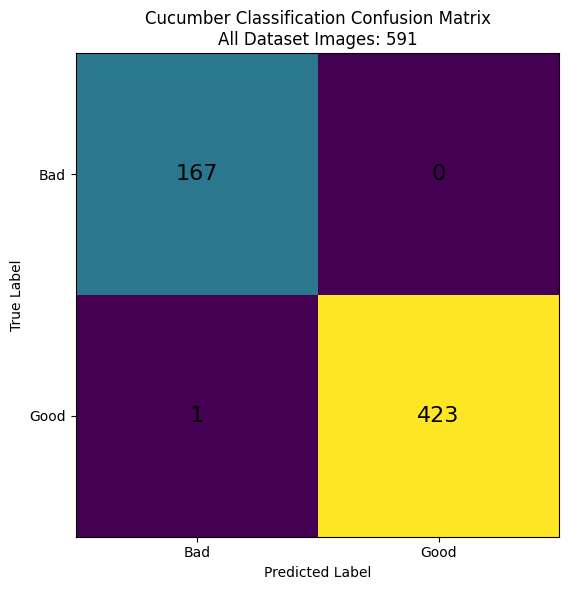

In [32]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(
    df_all["True Label"],
    df_all["Predicted Label"],
    labels=classes
)

print("Confusion Matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(8, 6))

ax.imshow(cm)

ax.set_xticks(np.arange(len(classes)))
ax.set_yticks(np.arange(len(classes)))

ax.set_xticklabels(classes)
ax.set_yticklabels(classes)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

ax.set_title(
    f"Cucumber Classification Confusion Matrix\n"
    f"All Dataset Images: {len(df_all)}"
)

for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=16
        )

plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# Make sure the order is always the same
matrix_labels = classes

cm = confusion_matrix(
    df_all["True Label"],
    df_all["Predicted Label"],
    labels=matrix_labels
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[167   0]
 [  1 423]]


In [35]:
print("Total images evaluated:", len(df_all))
print("Total confusion matrix samples:", cm.sum())

Total images evaluated: 591
Total confusion matrix samples: 591


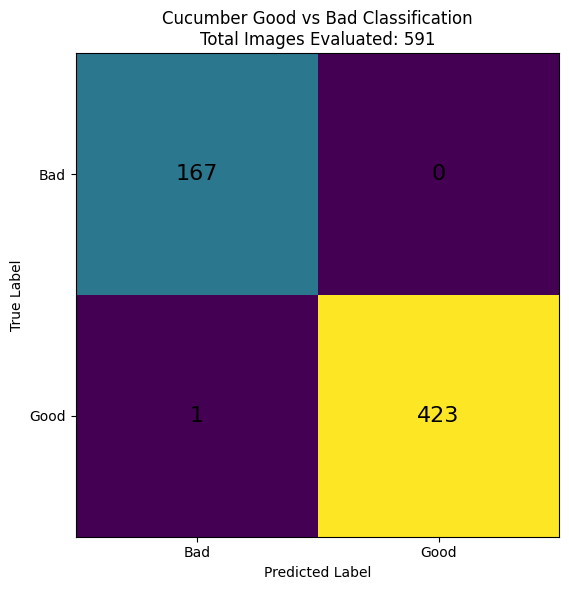

In [57]:
fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(cm)

# Axis labels
ax.set_xticks(np.arange(len(matrix_labels)))
ax.set_yticks(np.arange(len(matrix_labels)))

ax.set_xticklabels(matrix_labels)
ax.set_yticklabels(matrix_labels)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

# Accurate number of evaluated images
total_images_evaluated = cm.sum()

ax.set_title(
    "Cucumber Good vs Bad Classification\n"
    f"Total Images Evaluated: {total_images_evaluated}"
)

# Put numbers inside each cell
for i in range(len(matrix_labels)):
    for j in range(len(matrix_labels)):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=16
        )

plt.tight_layout()
plt.show()

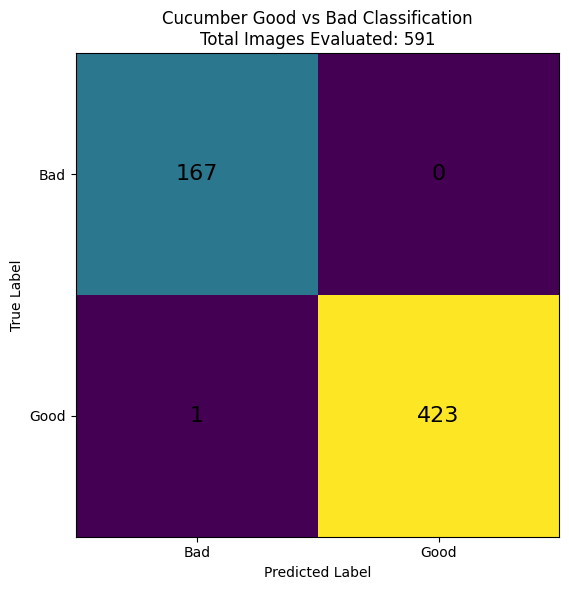

Confusion matrix saved to:
/content/cucumber_confusion_matrix.png


In [58]:
confusion_matrix_path = (
    "/content/cucumber_confusion_matrix.png"
)

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(cm)

ax.set_xticks(
    np.arange(len(matrix_labels))
)

ax.set_yticks(
    np.arange(len(matrix_labels))
)

ax.set_xticklabels(matrix_labels)
ax.set_yticklabels(matrix_labels)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

# Get the exact number of images evaluated
total_images_evaluated = cm.sum()

ax.set_title(
    "Cucumber Good vs Bad Classification\n"
    f"Total Images Evaluated: {total_images_evaluated}"
)

for i in range(len(matrix_labels)):
    for j in range(len(matrix_labels)):

        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=16
        )

plt.tight_layout()

plt.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved to:")
print(confusion_matrix_path)

In [38]:
from google.colab import files

files.download(
    confusion_matrix_path
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(
    df_all["True Label"],
    df_all["Predicted Label"]
)

print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 99.83%


In [40]:
from sklearn.metrics import classification_report

report = classification_report(
    df_all["True Label"],
    df_all["Predicted Label"],
    labels=classes,
    target_names=classes,
    digits=4
)

print(report)

              precision    recall  f1-score   support

         Bad     0.9940    1.0000    0.9970       167
        Good     1.0000    0.9976    0.9988       424

    accuracy                         0.9983       591
   macro avg     0.9970    0.9988    0.9979       591
weighted avg     0.9983    0.9983    0.9983       591



In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_true = df_all["True Label"]
y_pred = df_all["Predicted Label"]

accuracy = accuracy_score(y_true, y_pred)

precision_weighted = precision_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

recall_weighted = recall_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

f1_weighted = f1_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

precision_macro = precision_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

print("====================================")
print("MODEL PERFORMANCE")
print("====================================")

print(f"Accuracy          : {accuracy * 100:.2f}%")
print(f"Weighted Precision: {precision_weighted * 100:.2f}%")
print(f"Weighted Recall   : {recall_weighted * 100:.2f}%")
print(f"Weighted F1-Score : {f1_weighted * 100:.2f}%")

print("\nMacro Metrics")
print(f"Macro Precision   : {precision_macro * 100:.2f}%")
print(f"Macro Recall      : {recall_macro * 100:.2f}%")
print(f"Macro F1-Score    : {f1_macro * 100:.2f}%")

MODEL PERFORMANCE
Accuracy          : 99.83%
Weighted Precision: 99.83%
Weighted Recall   : 99.83%
Weighted F1-Score : 99.83%

Macro Metrics
Macro Precision   : 99.70%
Macro Recall      : 99.88%
Macro F1-Score    : 99.79%


In [43]:
from sklearn.metrics import classification_report, confusion_matrix

print("Total samples:", len(y_true))
print("Correct predictions:", (y_true == y_pred).sum())
print("Wrong predictions:", (y_true != y_pred).sum())

print("\n====================================")
print("CLASSIFICATION REPORT")
print("====================================")

print(classification_report(
    y_true,
    y_pred,
    digits=4,
    zero_division=0
))

print("\n====================================")
print("CONFUSION MATRIX")
print("====================================")

print(confusion_matrix(y_true, y_pred))

Total samples: 591
Correct predictions: 590
Wrong predictions: 1

CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Bad     0.9940    1.0000    0.9970       167
        Good     1.0000    0.9976    0.9988       424

    accuracy                         0.9983       591
   macro avg     0.9970    0.9988    0.9979       591
weighted avg     0.9983    0.9983    0.9983       591


CONFUSION MATRIX
[[167   0]
 [  1 423]]


In [44]:
wrong = df_all[df_all["True Label"] != df_all["Predicted Label"]]

print("Number of wrong predictions:", len(wrong))
print(wrong)

Number of wrong predictions: 1
                  Image True Label Predicted Label  Confidence  Split
266  train_Good_196.jpg       Good             Bad    0.546413  train


In [45]:
print(df_all["Split"].value_counts())

Split
train    472
test      60
val       59
Name: count, dtype: int64


In [46]:
from sklearn.metrics import accuracy_score

for split in df_all["Split"].unique():
    split_df = df_all[df_all["Split"] == split]

    acc = accuracy_score(
        split_df["True Label"],
        split_df["Predicted Label"]
    )

    print(f"{split}: {acc * 100:.2f}%")

train: 99.79%
val: 100.00%
test: 100.00%


In [47]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

for split in ["train", "val", "test"]:
    split_df = df_all[df_all["Split"] == split]

    if len(split_df) == 0:
        continue

    y_true_split = split_df["True Label"]
    y_pred_split = split_df["Predicted Label"]

    print("\n====================================")
    print(f"{split.upper()} PERFORMANCE")
    print("====================================")

    print(f"Samples: {len(split_df)}")
    print(f"Accuracy: {accuracy_score(y_true_split, y_pred_split) * 100:.2f}%")

    print("\nClassification Report:")
    print(classification_report(
        y_true_split,
        y_pred_split,
        digits=4,
        zero_division=0
    ))


TRAIN PERFORMANCE
Samples: 472
Accuracy: 99.79%

Classification Report:
              precision    recall  f1-score   support

         Bad     0.9925    1.0000    0.9963       133
        Good     1.0000    0.9971    0.9985       339

    accuracy                         0.9979       472
   macro avg     0.9963    0.9985    0.9974       472
weighted avg     0.9979    0.9979    0.9979       472


VAL PERFORMANCE
Samples: 59
Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

         Bad     1.0000    1.0000    1.0000        17
        Good     1.0000    1.0000    1.0000        42

    accuracy                         1.0000        59
   macro avg     1.0000    1.0000    1.0000        59
weighted avg     1.0000    1.0000    1.0000        59


TEST PERFORMANCE
Samples: 60
Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

         Bad     1.0000    1.0000    1.0000        17
        Good     1.00

In [49]:
model.save("/content/cucumber_model.keras")